# Day 5: Hourly Order Demand Forecasting

## Objective

The objective is to analyze historical Uber Eats order patterns and forecast future hourly order demand.

This analysis includes:

1. Loading and preparing order timestamps.
2. Aggregating order counts into hourly intervals.
3. Exploring demand trends and seasonality.
4. Testing stationarity using the Augmented Dickey-Fuller (ADF) test.
5. Applying differencing where required.
6. Building ARIMA and Prophet forecasting models.
7. Evaluating forecasts using MAE, RMSE, and MAPE.
8. Providing business recommendations for demand planning.

**Dataset:** `data/raw/orders.csv`

**Tools:** Python, Pandas, Matplotlib, Statsmodels, Prophet, and Scikit-learn.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", None)

PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "data" / "raw").exists():
    PROJECT_DIR = Path.home() / "Projects" / "uber-eats-intelligence"

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
INSIGHTS_DIR = PROJECT_DIR / "reports" / "insights"
MODELS_DIR = PROJECT_DIR / "models"

for folder in [PROCESSED_DIR, FIGURES_DIR, INSIGHTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: /home/nineleaps/Projects/uber-eats-intelligence


## Loading and Inspecting Order Data

We will load the orders dataset and examine its structure, timestamps, and order statuses.

The order timestamp is essential because demand forecasting requires observations arranged in chronological order. We will count all placed orders as demand, including orders that were later cancelled.

In [2]:
orders = pd.read_csv(RAW_DIR / "orders.csv")

print("Dataset shape:", orders.shape)
print("\nColumns:")
print(orders.columns.tolist())

print("\nFirst five records:")
print(orders.head())

print("\nMissing values:")
print(orders.isnull().sum())

print("\nOrder statuses:")
print(orders["order_status"].value_counts())

Dataset shape: (5000, 7)

Columns:
['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'number_of_items', 'order_status']

First five records:
   order_id  customer_id  restaurant_id      order_timestamp  order_amount  \
0         1          145             32  2026-02-11 18:07:00        148.95   
1         2          447             32  2026-03-30 02:35:00        860.38   
2         3          374             37  2026-02-16 12:12:00        590.54   
3         4          375             53  2026-03-22 09:29:00        929.83   
4         5          139             51  2026-03-07 22:30:00        867.50   

   number_of_items order_status  
0                8    Completed  
1                3    Completed  
2                3    Cancelled  
3                1    Completed  
4                6    Completed  

Missing values:
order_id           0
customer_id        0
restaurant_id      0
order_timestamp    0
order_amount       0
number_of_items    0
order_status 

In [3]:
orders["order_timestamp"] = pd.to_datetime(
    orders["order_timestamp"],
    errors="coerce"
)

orders = orders.dropna(subset=["order_timestamp"]).copy()

orders = orders.drop_duplicates(subset=["order_id"])

orders = orders.sort_values("order_timestamp")

print("Valid orders:", len(orders))
print("Earliest order:", orders["order_timestamp"].min())
print("Latest order:", orders["order_timestamp"].max())
print(
    "Date range (days):",
    (orders["order_timestamp"].max() -
     orders["order_timestamp"].min()).days
)

Valid orders: 5000
Earliest order: 2026-01-01 00:54:00
Latest order: 2026-03-31 23:57:00
Date range (days): 89


## Hourly Demand Aggregation

We will group individual orders into hourly intervals and count the number of orders placed during each hour.

Hours without recorded orders will be represented by zero, assuming the dataset covers those hours completely. This produces a continuous time series suitable for forecasting models.

In [4]:
hourly_demand = (
    orders.set_index("order_timestamp")
    .resample("h")
    .size()
    .rename("order_count")
    .asfreq("h", fill_value=0)
    .to_frame()
)

print("Hourly observations:", len(hourly_demand))
print("\nFirst five hours:")
print(hourly_demand.head())

print("\nHourly demand statistics:")
print(hourly_demand["order_count"].describe())

hourly_demand.to_csv(
    PROCESSED_DIR / "hourly_order_demand.csv"
)

Hourly observations: 2160

First five hours:
                     order_count
order_timestamp                 
2026-01-01 00:00:00            1
2026-01-01 01:00:00            0
2026-01-01 02:00:00            4
2026-01-01 03:00:00            0
2026-01-01 04:00:00            1

Hourly demand statistics:
count    2160.000000
mean        2.314815
std         1.521793
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         8.000000
Name: order_count, dtype: float64


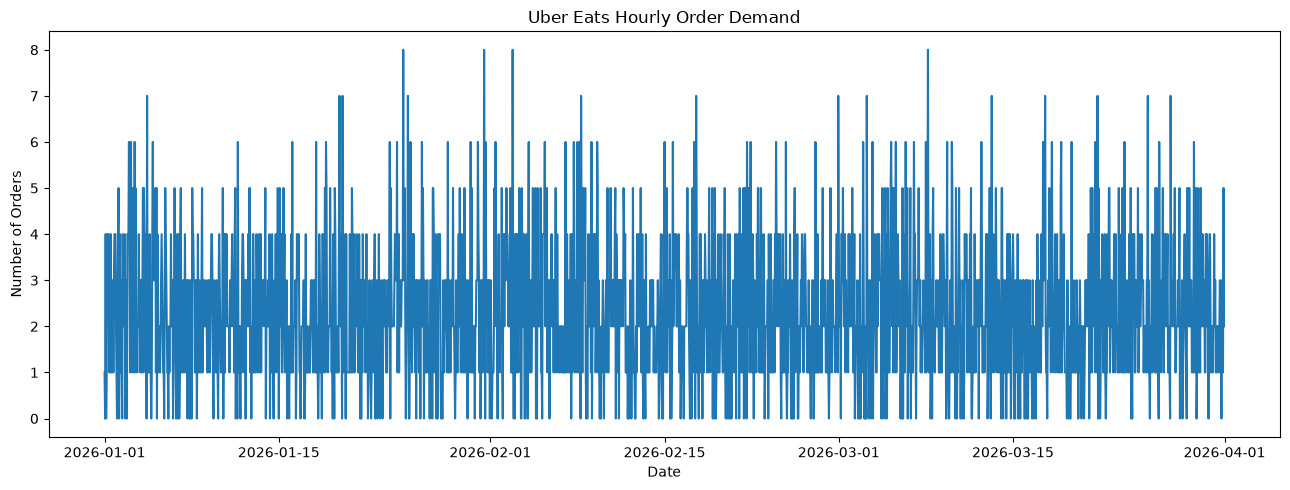

In [5]:
plt.figure(figsize=(13, 5))

plt.plot(
    hourly_demand.index,
    hourly_demand["order_count"]
)

plt.title("Uber Eats Hourly Order Demand")
plt.xlabel("Date")
plt.ylabel("Number of Orders")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "hourly_order_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

hour
0     2.36
1     2.20
2     2.51
3     2.46
4     2.16
5     2.10
6     2.59
7     2.26
8     2.29
9     2.33
10    2.44
11    2.29
12    2.51
13    2.21
14    2.29
15    2.47
16    2.01
17    2.33
18    1.94
19    2.20
20    2.52
21    2.31
22    2.60
23    2.18
Name: order_count, dtype: float64


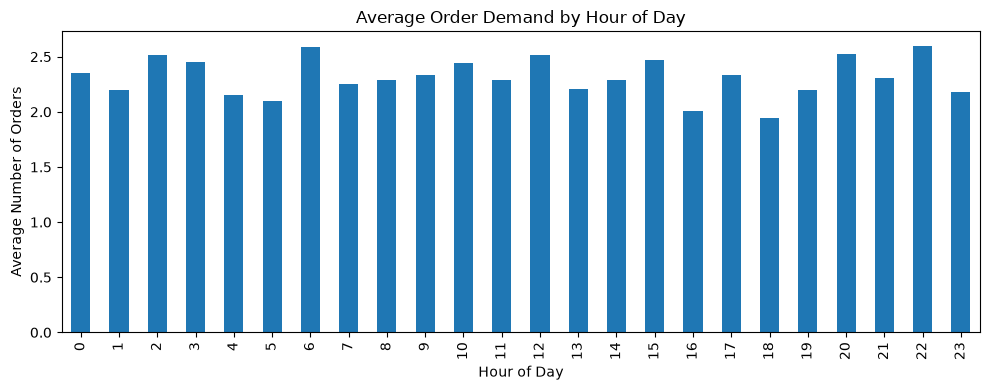

In [6]:
hourly_pattern = (
    hourly_demand
    .assign(hour=hourly_demand.index.hour)
    .groupby("hour")["order_count"]
    .mean()
)

print(hourly_pattern.round(2))

hourly_pattern.plot(
    kind="bar",
    figsize=(10, 4)
)

plt.title("Average Order Demand by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Orders")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "average_demand_by_hour.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Time-Series Decomposition

Time-series decomposition separates observed order demand into trend, seasonal, and residual components.

We will examine a daily seasonal cycle of 24 hours. This helps us understand whether the dataset contains repeating hourly patterns.

Because the data is synthetic, any identified patterns should be interpreted cautiously.

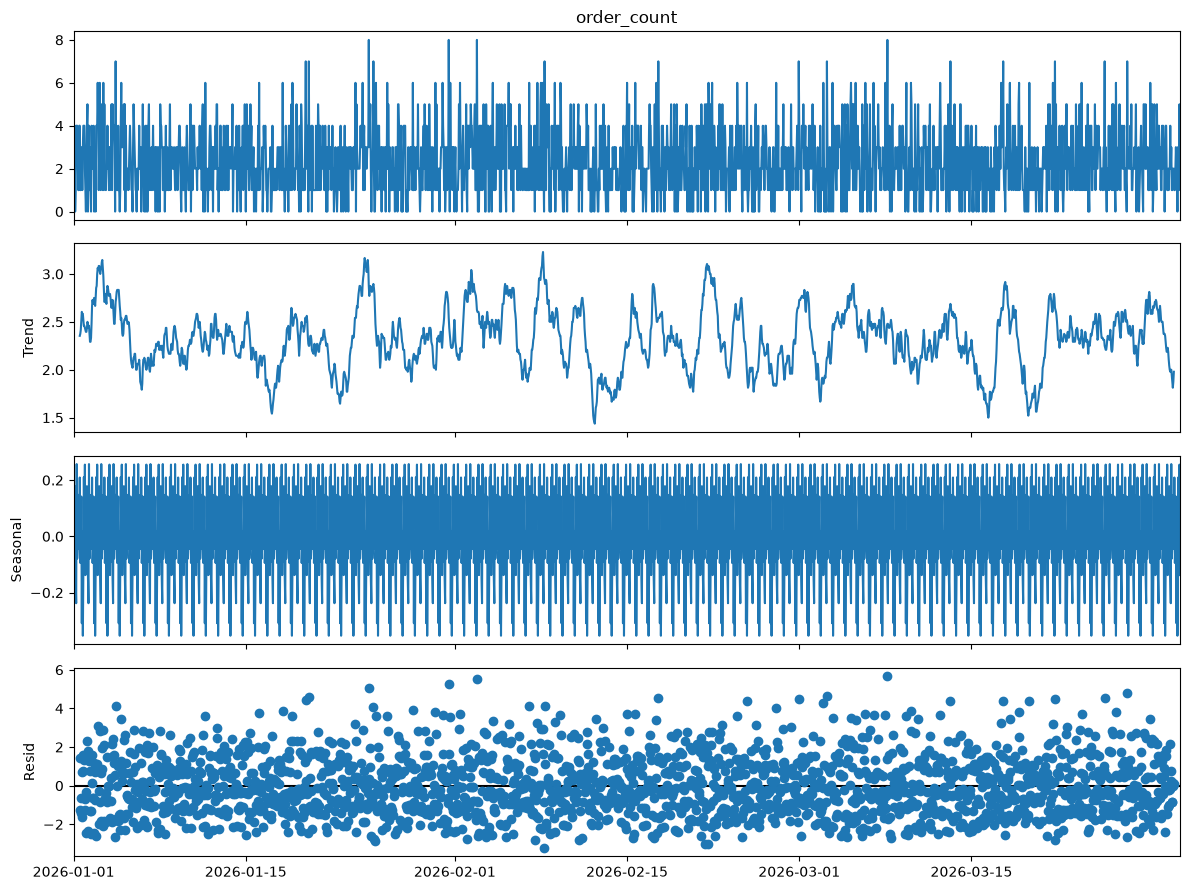

In [7]:
if len(hourly_demand) >= 48:
    decomposition = seasonal_decompose(
        hourly_demand["order_count"],
        model="additive",
        period=24
    )

    fig = decomposition.plot()
    fig.set_size_inches(12, 9)
    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / "hourly_demand_decomposition.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
else:
    print("Not enough observations for daily decomposition.")

## Stationarity and ADF Test

A stationary time series has statistical properties that remain relatively stable over time.

The Augmented Dickey-Fuller (ADF) test helps assess whether the series contains a unit root.

- **Null hypothesis:** The series has a unit root.
- **p-value below 0.05:** Reject the unit-root null hypothesis.
- **p-value of 0.05 or above:** There is insufficient evidence to reject the null hypothesis.

If the series appears non-stationary, we will apply first-order differencing and repeat the test.

In [8]:
def run_adf_test(series, name):
    result = adfuller(series.dropna())

    print(f"\nADF Test: {name}")
    print("ADF Statistic:", round(result[0], 4))
    print("p-value:", round(result[1], 4))
    print("Lags used:", result[2])

    if result[1] < 0.05:
        print("Result: Reject the unit-root null hypothesis.")
    else:
        print("Result: Cannot reject the unit-root null hypothesis.")

    return result[1]


adf_pvalue = run_adf_test(
    hourly_demand["order_count"],
    "Original Hourly Demand"
)


ADF Test: Original Hourly Demand
ADF Statistic: -47.2333
p-value: 0.0
Lags used: 0
Result: Reject the unit-root null hypothesis.


/tmp/ipykernel_127380/2234486382.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


In [9]:
if adf_pvalue >= 0.05:
    differenced_demand = (
        hourly_demand["order_count"].diff().dropna()
    )

    print("First-order differencing applied.")

    run_adf_test(
        differenced_demand,
        "Differenced Hourly Demand"
    )

    d_value = 1
else:
    differenced_demand = hourly_demand["order_count"].copy()
    d_value = 0
    print("Differencing not required based on the ADF test.")

print("ARIMA differencing order:", d_value)

Differencing not required based on the ADF test.
ARIMA differencing order: 0


## Chronological Train/Test Split

Unlike ordinary regression, time-series forecasting must preserve chronological order.

We will train the models using the first 80% of hourly observations and evaluate predictions against the final 20%.

This simulates forecasting later periods from earlier observations and avoids randomly mixing future observations into training data.

In [10]:
series = hourly_demand["order_count"].astype(float)

split_index = int(len(series) * 0.80)

train = series.iloc[:split_index]
test = series.iloc[split_index:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 1728
Testing observations: 432

Training period:
2026-01-01 00:00:00 to 2026-03-13 23:00:00

Testing period:
2026-03-14 00:00:00 to 2026-03-31 23:00:00


In [11]:
hourly_averages = train.groupby(train.index.hour).mean()

baseline_predictions = pd.Series(
    test.index.hour.map(hourly_averages),
    index=test.index,
    name="Baseline"
).fillna(train.mean())

print("Baseline forecast created.")
print(baseline_predictions.head())

Baseline forecast created.
order_timestamp
2026-03-14 00:00:00    2.347222
2026-03-14 01:00:00    2.222222
2026-03-14 02:00:00    2.513889
2026-03-14 03:00:00    2.500000
2026-03-14 04:00:00    1.986111
Freq: h, Name: Baseline, dtype: float64


## ARIMA Forecasting

ARIMA stands for Autoregressive Integrated Moving Average.

The model uses historical observations and statistical relationships to forecast future demand.

Its parameters are:

- **p:** Number of autoregressive lags.
- **d:** Number of differences.
- **q:** Number of moving-average lags.

We will begin with a simple ARIMA configuration and evaluate its forecasts against the chronological test set. This is an initial model rather than a fully tuned configuration.

In [12]:
arima_model = ARIMA(
    train,
    order=(2, d_value, 2)
)

arima_result = arima_model.fit()

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:            order_count   No. Observations:                 1728
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -3184.504
Date:                Wed, 28 Oct 2026   AIC                           6381.008
Time:                        15:01:06   BIC                           6413.736
Sample:                    01-01-2026   HQIC                          6393.114
                         - 03-13-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.3254      0.040     58.784      0.000       2.248       2.403
ar.L1         -0.5260      0.042    -12.440      0.000      -0.609      -0.443
ar.L2         -0.9410      0.042    -22.577      0.0

In [13]:
arima_predictions = arima_result.forecast(
    steps=len(test)
)

arima_predictions.index = test.index

print("ARIMA forecast generated.")
print(arima_predictions.head())

ARIMA forecast generated.
order_timestamp
2026-03-14 00:00:00    2.379233
2026-03-14 01:00:00    2.403797
2026-03-14 02:00:00    2.233475
2026-03-14 03:00:00    2.299959
2026-03-14 04:00:00    2.425252
Freq: h, Name: predicted_mean, dtype: float64


## Prophet Forecasting

Prophet is a forecasting model designed to represent trends and recurring seasonal patterns.

We will prepare the hourly demand dataset using Prophet's required column names:

- `ds`: Timestamp.
- `y`: Observed order count.

We will enable daily and weekly seasonality and compare Prophet's forecasts with ARIMA and the baseline.

Prophet's default additive forecasts may produce negative values for a nonnegative target, so we will clip negative predictions to zero for evaluation.

In [14]:
from prophet import Prophet

print("Prophet imported successfully.")

Importing plotly failed. Interactive plots will not work.


Prophet imported successfully.


In [15]:
%pip install prophet

Note: you may need to restart the kernel to use updated packages.


In [16]:
prophet_train = train.reset_index()
prophet_train.columns = ["ds", "y"]

prophet_model = Prophet(
    daily_seasonality=True,
    weekly_seasonality=len(train) >= 24 * 14,
    yearly_seasonality=False
)

prophet_model.fit(prophet_train)

print("Prophet training completed.")

15:06:27 - cmdstanpy - INFO - Chain [1] start processing
15:06:27 - cmdstanpy - INFO - Chain [1] done processing


Prophet training completed.


In [17]:
prophet_future = pd.DataFrame({
    "ds": test.index
})

prophet_forecast = prophet_model.predict(prophet_future)

prophet_predictions = pd.Series(
    np.maximum(prophet_forecast["yhat"].to_numpy(), 0),
    index=test.index,
    name="Prophet"
)

print("Prophet forecast generated.")
print(prophet_predictions.head())

Prophet forecast generated.
order_timestamp
2026-03-14 00:00:00    2.253904
2026-03-14 01:00:00    2.259789
2026-03-14 02:00:00    2.296399
2026-03-14 03:00:00    2.324002
2026-03-14 04:00:00    2.322000
Freq: h, Name: Prophet, dtype: float64


## Forecast Model Evaluation

We will compare the baseline, ARIMA, and Prophet forecasts using:

- **MAE:** Mean Absolute Error, measured in orders per hour.
- **RMSE:** Root Mean Squared Error, which penalizes large errors more heavily.
- **MAPE:** Mean Absolute Percentage Error, calculated only for hours with nonzero actual demand.

MAPE is undefined when actual demand is zero. Because hourly demand can contain many zero-order periods, we will also report the number of nonzero observations used in the MAPE calculation. MAE and RMSE will be the primary comparison metrics.

In [18]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    nonzero = actual != 0

    if nonzero.any():
        mape = np.mean(
            np.abs(
                (actual[nonzero] - predicted[nonzero])
                / actual[nonzero]
            )
        ) * 100
    else:
        mape = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_Percent": mape,
        "MAPE_Valid_Hours": int(nonzero.sum())
    }


forecast_results = []

forecast_models = {
    "Hourly Baseline": baseline_predictions,
    "ARIMA": arima_predictions,
    "Prophet": prophet_predictions
}

for name, prediction in forecast_models.items():
    metrics = calculate_metrics(test, prediction)

    forecast_results.append({
        "Model": name,
        **metrics
    })

forecast_comparison = pd.DataFrame(
    forecast_results
).sort_values("MAE")

print(forecast_comparison.round(3).to_string(index=False))

forecast_comparison.to_csv(
    INSIGHTS_DIR / "forecast_model_comparison.csv",
    index=False
)

          Model   MAE  RMSE  MAPE_Percent  MAPE_Valid_Hours
        Prophet 1.180 1.483        54.921               394
          ARIMA 1.186 1.476        54.962               394
Hourly Baseline 1.200 1.504        55.529               394


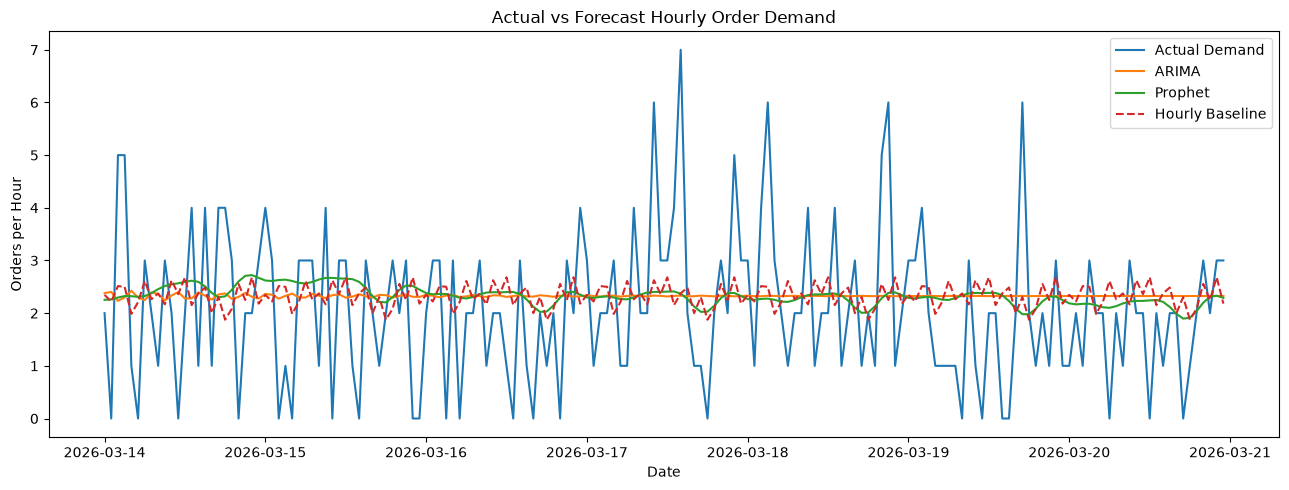

In [19]:
plt.figure(figsize=(13, 5))

# Show up to the first seven days of the test period
plot_hours = min(168, len(test))

plt.plot(
    test.index[:plot_hours],
    test.iloc[:plot_hours],
    label="Actual Demand"
)

plt.plot(
    test.index[:plot_hours],
    arima_predictions.iloc[:plot_hours],
    label="ARIMA"
)

plt.plot(
    test.index[:plot_hours],
    prophet_predictions.iloc[:plot_hours],
    label="Prophet"
)

plt.plot(
    test.index[:plot_hours],
    baseline_predictions.iloc[:plot_hours],
    label="Hourly Baseline",
    linestyle="--"
)

plt.title("Actual vs Forecast Hourly Order Demand")
plt.xlabel("Date")
plt.ylabel("Orders per Hour")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "demand_forecast_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
forecast_predictions = pd.DataFrame({
    "timestamp": test.index,
    "actual_orders": test.values,
    "baseline_prediction": baseline_predictions.values,
    "arima_prediction": arima_predictions.values,
    "prophet_prediction": prophet_predictions.values
})

forecast_predictions.to_csv(
    PROCESSED_DIR / "hourly_demand_forecasts.csv",
    index=False
)

print("Forecast predictions saved.")

Forecast predictions saved.


In [23]:
import joblib

arima_result.save(
    str(MODELS_DIR / "arima_demand_model.pkl")
)

joblib.dump(
    prophet_model,
    MODELS_DIR / "prophet_demand_model.joblib"
)

print("ARIMA and Prophet models saved successfully.")

ARIMA and Prophet models saved successfully.


## Business Insights and Recommendations

### Forecasting Findings

The hourly order demand dataset was analyzed to identify time-based patterns and forecast future order volume.

A chronological train/test split was used to evaluate an hourly baseline, ARIMA, and Prophet.

The models were compared using MAE, RMSE, and MAPE, with zero-demand hours excluded from the MAPE calculation.

### Business Recommendations

1. **Driver Planning:** Use validated demand forecasts to help plan driver availability during higher-demand periods.
2. **Restaurant Preparation:** Share anticipated demand patterns with restaurants to support kitchen staffing and preparation.
3. **Peak-Hour Management:** Investigate hours with consistently high order volume and prepare operational resources accordingly.
4. **Forecast Monitoring:** Compare predicted and actual orders regularly to detect deteriorating model performance.
5. **Model Improvement:** Explore additional predictors, seasonal forecasting methods, and rolling-window validation.

### Limitations

The dataset is synthetic and may not contain realistic daily or weekly seasonality. Forecasting performance on synthetic orders does not establish real-world accuracy.

A single chronological test split provides an initial assessment, but rolling-origin validation would provide stronger evidence of future forecasting performance.

Forecasts should be evaluated against a simple baseline before being used for operational decisions.

In [24]:
required_files = [
    PROCESSED_DIR / "hourly_order_demand.csv",
    PROCESSED_DIR / "hourly_demand_forecasts.csv",
    INSIGHTS_DIR / "forecast_model_comparison.csv",
    FIGURES_DIR / "hourly_order_demand.png",
    FIGURES_DIR / "average_demand_by_hour.png",
    FIGURES_DIR / "demand_forecast_comparison.png",
    MODELS_DIR / "arima_demand_model.pkl",
    MODELS_DIR / "prophet_demand_model.joblib"
]

for path in required_files:
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status}: {path.relative_to(PROJECT_DIR)}")

FOUND: data/processed/hourly_order_demand.csv
FOUND: data/processed/hourly_demand_forecasts.csv
FOUND: reports/insights/forecast_model_comparison.csv
FOUND: reports/figures/hourly_order_demand.png
FOUND: reports/figures/average_demand_by_hour.png
FOUND: reports/figures/demand_forecast_comparison.png
FOUND: models/arima_demand_model.pkl
FOUND: models/prophet_demand_model.joblib
